# 05 - Interpretability

Goal: see what the models use to choose a category.

- **A. Text:** which words decide the category, for the SVM and for CamemBERT.
- **B. Fusion:** what the image adds to the final model, equal soft voting of CamemBERT, the SVM and the image.


## A. Text: which words decide the category?

We look at the two text models:
- **SVM:** it gives each word a weight for each category. We can read these weights directly.
- **CamemBERT:** it has no word weights. We remove one word at a time and see what changes.

### A1. Train the SVM

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES

data = pd.read_csv("../data/processed/text_train_processed.csv")
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]

# Settings chosen in notebook 03_2
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train = vectorizer.fit_transform(train["text_combined"])
X_validation = vectorizer.transform(validation["text_combined"])

model = LinearSVC(C=1, random_state=42).fit(X_train, train["prdtypecode"])

words = vectorizer.get_feature_names_out()
classes = list(model.classes_)
weights = model.coef_  # one row per category, one column per word

print(f"Words and word pairs: {len(words)}")
print(f"Categories: {len(classes)}")

Words and word pairs: 460326
Categories: 27


### A2. The SVM's top words for each category

For each category, the 8 words that push most toward it.

In [2]:
top_rows = []
for i, code_ in enumerate(classes):
    top = np.argsort(weights[i])[::-1][:8]
    top_rows.append({
        "Code": code_,
        "Category": CATEGORY_NAMES[code_],
        "Top words": ", ".join(words[top]),
    })

pd.DataFrame(top_rows).style.hide(axis="index")

Code,Category,Top words
10,Used Books,"edition de, and, in, der, die, cookbook, dico, und"
40,Games,"magideal, import, ensemble complet, la description, pal, simulator, essentials, quickio"
50,Game Accessories,"gaming, ps4, pour nintendo, manette, pour, skylanders, joystick, amiibo"
60,Consoles,"console, nom de, sony playstation, nom, pack xbox, 500 go, console de, bundle"
1140,Figurines,"figurine, shirt, magnet, figurines, gundam, mug, buste, watermelon"
1160,Cards,"carte, mtg, vf, vo, commune, pokemon, rare, attax"
1180,Wargames,"heroclix, warhammer, oop, miniatures, 40k, shadowrun, wargame, elfe"
1280,Toys,"peluche, puzzle, hélicoptère, poupée, doudou, playmobil, lego, kinder"
1281,Board Games,"propos, jeu, monopoly, tarot, cards, trivial, asmodee, cartes"
1300,RC Models,"générique, drone, maquette, 43, ho, dji, altaya, matchbox"


### Analysis

- Most top words make sense: *piscine* (pool) for Pool, *chien* (dog) for Pets, *warhammer* for Wargames.
- Some top words are seller names, such as *sweetheart93*. The model learned who sells what, which may not work for new sellers.
- For books, the top words are about writing style: New Books uses words from a book summary (*ce livre*, *auteur*), Used Books uses foreign words (*and*, *der*) because many used books have foreign titles.

### A3. Why the four book categories get mixed up

The top 10 words of each book category.

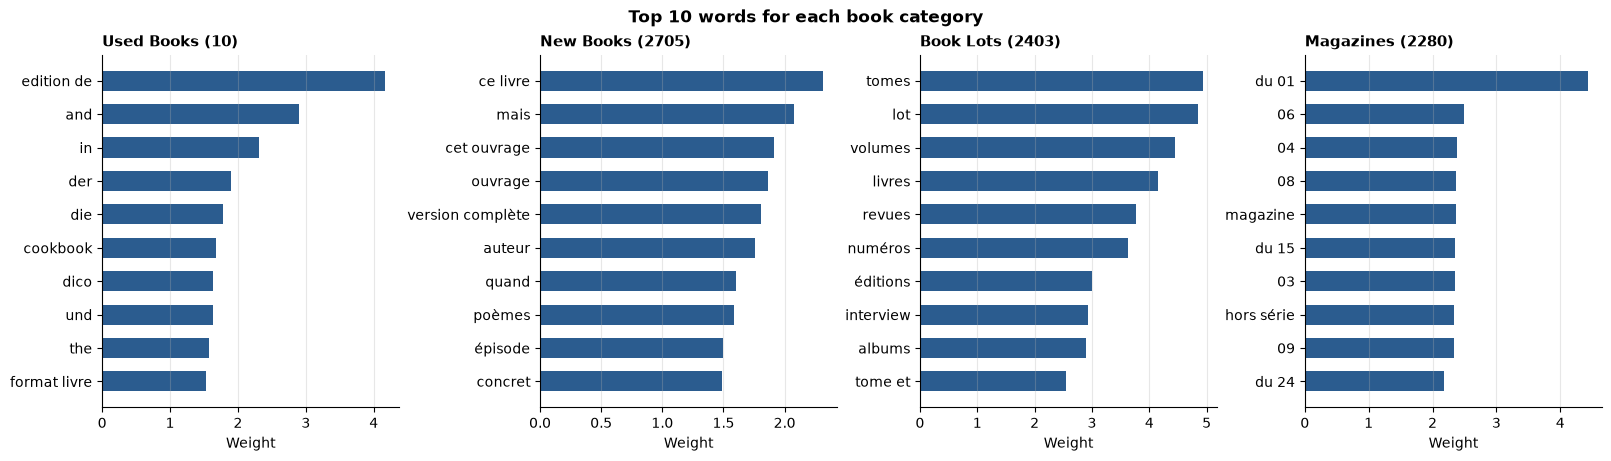

In [3]:
book_codes = [10, 2705, 2403, 2280]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
for ax, code_ in zip(axes, book_codes):
    row = weights[classes.index(code_)]
    top = np.argsort(row)[::-1][:10]
    ax.barh(words[top][::-1], row[top][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Weight")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Top 10 words for each book category", fontsize=12, fontweight="bold")
plt.show()

### Analysis

- Each book category has a few strong words: *lot* and *tomes* for Book Lots, dates such as *du 01* for Magazines.
- A book title without one of these words gives the SVM almost nothing to go on.
- This is why book categories make 7 of the 10 most confused pairs.

### A4. One SVM mistake, word by word

A used book that the SVM calls a book lot. Each bar shows how much one word pushes toward the category.

Title: la promenade au parc


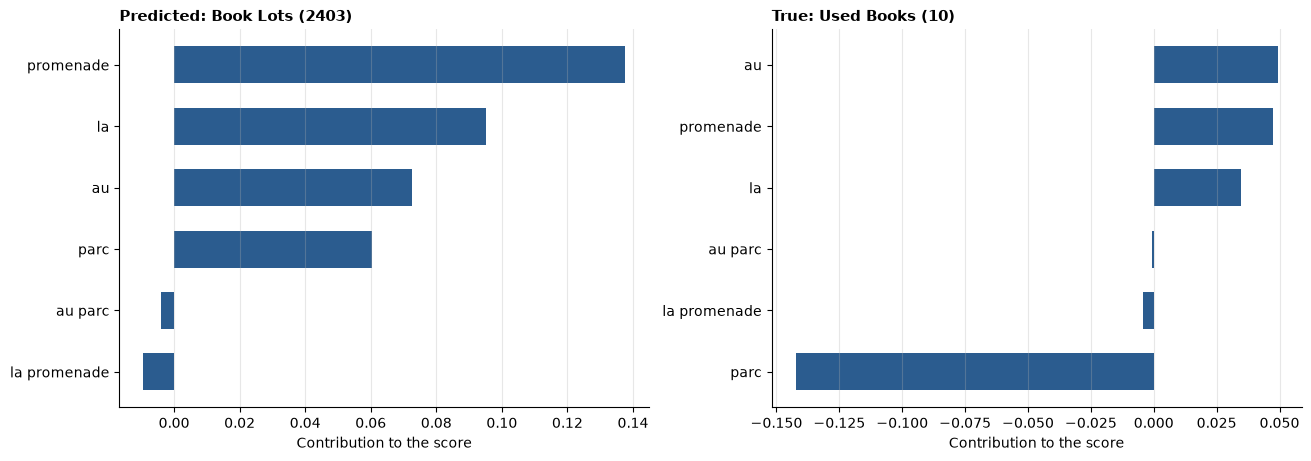

Score for Book Lots (2403): -0.50
Score for Used Books (10):  -0.68


In [4]:
predictions = model.predict(X_validation)
wrong = np.where((validation["prdtypecode"].to_numpy() == 10) & (predictions == 2403))[0]
idx = wrong[0]

x = X_validation[idx]
present = x.indices
print("Title:", validation["designation_clean"].iloc[idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, code_, label in [(axes[0], 2403, "Predicted"), (axes[1], 10, "True")]:
    contrib = x.data * weights[classes.index(code_)][present]
    order = np.argsort(contrib)[::-1][:8]
    ax.barh(words[present][order][::-1], contrib[order][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{label}: {CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Contribution to the score")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
plt.show()

scores = model.decision_function(x)[0]
print(f"Score for Book Lots (2403): {scores[classes.index(2403)]:.2f}")
print(f"Score for Used Books (10):  {scores[classes.index(10)]:.2f}")

### Analysis

- The title is only *la promenade au parc* ("the walk in the park"), with no description.
- None of these words is a book word, so both scores are low and close. Book Lots wins by a small margin.
- When the text is short and generic, a text model has nothing to go on. The image can help here (notebook 04).

### A5. Which words CamemBERT uses

CamemBERT has no word weights. So we remove one word at a time and see how much its confidence drops. A big drop means the word mattered.

Two short titles: one CamemBERT gets right, one it gets wrong.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

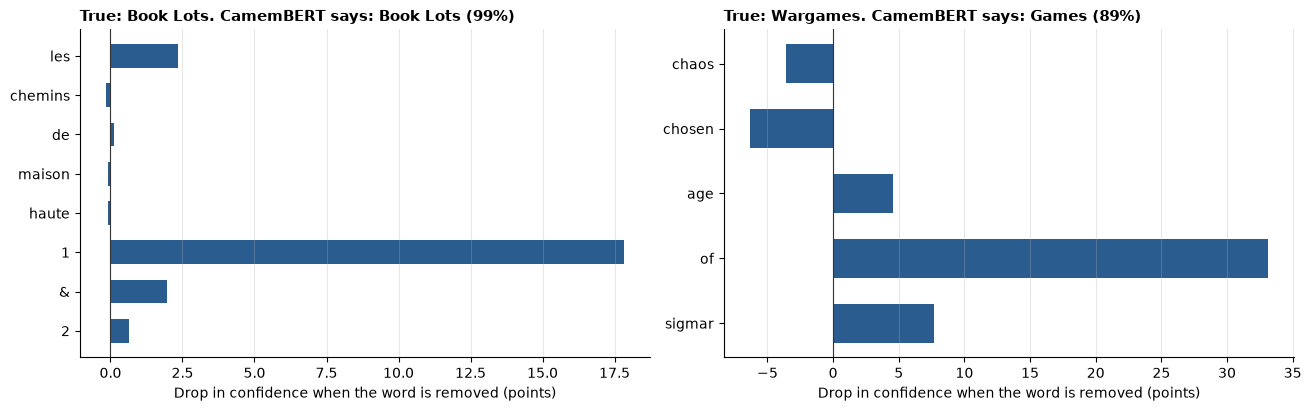

In [5]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("../models/camembert")
camembert = AutoModelForSequenceClassification.from_pretrained("../models/camembert").eval()


def camembert_probabilities(texts):
    with torch.no_grad():
        tokens = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
        return torch.softmax(camembert(**tokens).logits, dim=1).numpy()


def word_importance(text):
    """Drop in confidence for the predicted category when each word is removed."""
    words_in_text = text.split()
    full = camembert_probabilities([text])[0]
    predicted = int(full.argmax())
    without = camembert_probabilities([" ".join(words_in_text[:i] + words_in_text[i + 1:]) for i in range(len(words_in_text))])
    drops = (full[predicted] - without[:, predicted]) * 100
    return words_in_text, drops, classes[predicted], full[predicted]


examples = [("les chemins de maison haute 1 & 2", 2403), ("chaos chosen age of sigmar", 1180)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, (text, true_code) in zip(axes, examples):
    words_in_text, drops, predicted_code, confidence = word_importance(text)
    ax.barh(words_in_text[::-1], drops[::-1], color="#2b5c8f", height=0.6)
    ax.axvline(0, color="#333333", linewidth=0.8)
    ax.set_title(f"True: {CATEGORY_NAMES[true_code]}. CamemBERT says: {CATEGORY_NAMES[predicted_code]} ({confidence:.0%})",
                 loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Drop in confidence when the word is removed (points)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
plt.show()

### Analysis

- **Left (right answer):** removing *1* drops the confidence by 18 points. CamemBERT reads *1 & 2* as "volumes 1 and 2", so a lot of several books. The SVM got this one wrong.
- **Right (wrong answer):** *of* matters most (33 points). CamemBERT reads *age of ...* like a video game title (*Age of Empires*) and says Games. The SVM gets it right through *sigmar*, a rare Warhammer word.
- So the two text models make different mistakes. That is why combining them helps.

#### Text conclusion

- The SVM decides on single words: clear product words, but also seller names.
- CamemBERT reads words together. This helps for books, but a familiar pattern can mislead it.
- Short book titles with no clear word are hard for both.

## B. Fusion

The final model is equal soft voting (notebook 04): it averages the probabilities of CamemBERT, the SVM and the ConvNeXt image model, then takes the class with the highest average.

To see what the image adds, we compare soft voting with and without it, overall and per category. Nothing is fitted, so both are scored directly on the 16984 validation products.

In [6]:
from sklearn.metrics import f1_score

from src.metrics import compute_per_class_metrics

classes_str = [str(c) for c in classes]
fusion = validation[["row_id", "prdtypecode"]].merge(
    pd.read_csv("../data/processed/camembert_validation_probabilities.csv"), on="row_id")
P_camembert = fusion[classes_str].to_numpy()
P_svm = fusion[["row_id"]].merge(
    pd.read_csv("../data/processed/text_validation_probabilities.csv"), on="row_id")[classes_str].to_numpy()
convnext = pd.read_csv("../models/outputs/03_7_convnext_tiny_optimized_validation_predictions.csv")
convnext.columns = [c.strip() for c in convnext.columns]
P_image = fusion[["row_id"]].merge(convnext, on="row_id")[[f"prob_{c}" for c in classes]].to_numpy()
y_fusion = fusion["prdtypecode"].to_numpy()

class_codes = np.array(classes)
with_image = class_codes[(P_camembert + P_svm + P_image).argmax(axis=1)]
without_image = class_codes[(P_camembert + P_svm).argmax(axis=1)]
print(f"Weighted F1 with image:    {f1_score(y_fusion, with_image, average='weighted'):.4f}")
print(f"Weighted F1 without image: {f1_score(y_fusion, without_image, average='weighted'):.4f}")

Weighted F1 with image:    0.8941
Weighted F1 without image: 0.8864


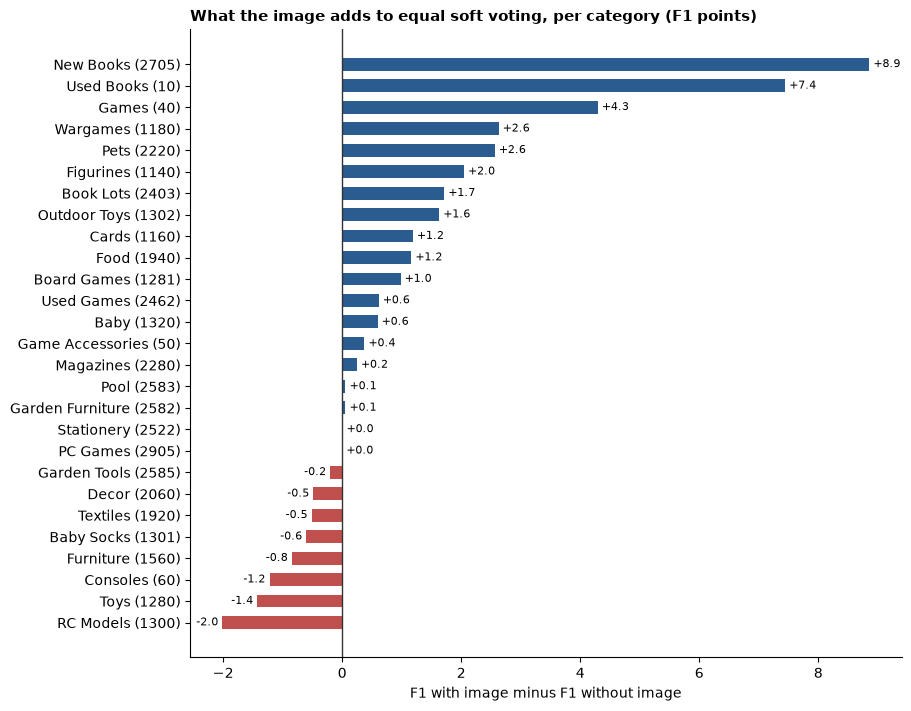

In [7]:
gain = (compute_per_class_metrics(y_fusion, with_image, classes)["f1"].to_numpy()
        - compute_per_class_metrics(y_fusion, without_image, classes)["f1"].to_numpy()) * 100
gain = pd.Series(gain, index=[f"{CATEGORY_NAMES[c]} ({c})" for c in classes]).sort_values()

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
bars = ax.barh(gain.index, gain.values, color=["#2b5c8f" if g >= 0 else "#c0504d" for g in gain.values], height=0.6)
ax.bar_label(bars, labels=[f"{g:+.1f}" for g in gain.values], padding=3, fontsize=8)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("What the image adds to equal soft voting, per category (F1 points)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("F1 with image minus F1 without image")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Analysis

- Without the image (CamemBERT and SVM only), soft voting scores 0.8864. With it, 0.8941 (+0.77 points).
- The image matters most on New Books (+8.9 points) and Used Books (+7.4). Text often cannot tell if a book is new or used; the cover can.
- It also helps on Games (+4.3), where the box picture shows what the text does not say.
- For most other categories the image adds little. It costs at most 2.0 points (RC Models), then Toys (-1.4) and Consoles (-1.2).

## Conclusion

- **Text:** the SVM relies on single words, including seller names. CamemBERT reads words together, which helps for books.
- **Fusion:** text does most of the work. The image adds little overall, but it is decisive for telling new books from used books.
